# 05 · Final test on later data, and Prophet, ETS and ARIMA as challengers

Notebook 03 chose the method and reported its accuracy on the same 47 forecast dates. Picking the
best of 26 candidates and scoring the winner where it was picked flatters it. This notebook fixes
that in the standard way: **choose on early dates, then score once on later ones**, with the rules
written down first in [docs/final_test_plan.md](../docs/final_test_plan.md).

It also runs three standard single-series models through the same backtest: **Prophet**,
**AutoETS** and **AutoARIMA**. And it saves today's forecasts from every method, so they can be
scored as new months arrive: the only test data that no design choice has seen.

| | |
|---|---|
| **Question** | Does the method picked on 2014-2021 still beat the simple rules on 2023-2025, and how do Prophet, ETS and ARIMA compare? |
| **Answer** | No. The rule picks zillow_style+mint_shrink, which then fails the test plainly: 7.6 pp metro 12-month error against 4.5 pp for momentum, better on only 2 of 11 forecast dates. No candidate passes: the best of the 26 on the test dates is the no-change forecast (4.3 pp), and combo+bottom_up, the README's model, ties momentum (4.5 pp, 5 of 11 dates). Compared date by date, even the full backtest's 12-month gain over momentum could be chance (95% interval -4% to +33%), while the 1- and 3-month gains are clear (60% and 35% for metros). Of the challengers, a damped-trend ETS is best on 2023-25 (3.4 pp on the 50 largest metros, better than momentum on 10 of 11 dates); Prophet is the worst, even after tuning on 2014-2021 (6.3 pp). |
| **Next** | Damped ETS joins the candidates, and the forecasts frozen in section 5 are the next real test. |

In [1]:
import logging
import os
import sys
import warnings
from pathlib import Path

warnings.filterwarnings("ignore", message="IProgress not found")    # tqdm, via statsforecast
logging.getLogger("prophet.plot").disabled = True
logging.getLogger("cmdstanpy").disabled = True

ROOT = Path.cwd() if (Path.cwd() / "src").exists() else Path.cwd().parent
os.chdir(ROOT)
sys.path.insert(0, str(ROOT / "src"))

import matplotlib.dates as mdates
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

from housing import backtest as bt
from housing import finaltest as ft
from housing import models, panel, scenarios
from housing.config import data_dirs, metrics_dir, use_synthetic
from housing.pipeline import eval_origins, run_all
from housing.plots import COLORS, save, style, write_metrics

style()
if use_synthetic():
    print("SYNTHETIC DATA: numbers below are made up (CI run).")
proc = data_dirs()[1]
Y, S_df, tags, nodes = panel.load_hierarchy()
L = bt.log_wide(Y)
evo = eval_origins(L)
if (proc / "backtest_models.parquet").exists() and not use_synthetic():
    res = pd.read_parquet(proc / "backtest_models.parquet")      # scripts/run_models.py
else:
    res = run_all(save=False)["long"]
res["level"] = pd.Categorical(ft.level_of_id(res["unique_id"]))
res["period"] = pd.Categorical(ft.period(res["origin"]).to_numpy())
print(res.groupby("period", observed=True)["origin"].nunique().rename("forecast dates").to_string())

period
gap           4
selection    32
test         11


## 1. Choose on 2014-2021 only

The same rule as notebook 03 (lowest RMSE averaged over the four levels and four horizons, among the
coherent methods), applied to the 32 selection dates alone. The 2022 dates are left out: their
12-month outcomes fall inside the test period.

In [2]:
sel = ft.rmse_table(res[res["period"] == "selection"]).rename("rmse_pp").reset_index()
chosen, avg = ft.choose(sel)
write_metrics("05_selection", {"chosen": chosen, "avg_rmse_pp": float(avg.iloc[0]),
                               "runner_up": str(avg.index[1]), "runner_up_avg_rmse_pp": float(avg.iloc[1]),
                               "selection_dates": int(res.loc[res["period"] == "selection", "origin"].nunique())})
print(f"Chosen on 2014-2021: {chosen}")
avg.head(6).round(3).to_frame("average RMSE, selection (pp)")

Chosen on 2014-2021: zillow_style+mint_shrink


,"average RMSE, selection (pp)"
method,
zillow_style+mint_shrink,1.943
ar2+bottom_up,1.970
ar2+wls_var,1.975
combo+bottom_up,1.989
combo+wls_var,1.990
zillow_style+wls_var,2.005


The top four are within 0.05 pp of each other, so on 2014-2021 the choice is close to a coin
flip among very different models: a trend-follower (zillow_style), a per-place ARIMA and the
combination.

## 2. Score once on 2023-2025: the verdict

Pass rule, fixed in advance: for metros at 12 months, lower RMSE than momentum over the 11 test
dates **and** lower RMSE on at least 7 of them.

In [3]:
test = res[res["period"] == "test"]
by_date = ft.rmse_by_origin(test, [chosen, "combo+bottom_up", "momentum", "naive"])
v = ft.verdict(by_date, chosen)
write_metrics("05_verdict", v)
print(f"{chosen}: {v['rmse_chosen_pp']:.2f} pp vs momentum {v['rmse_reference_pp']:.2f} pp; "
      f"better on {v['wins']} of {v['test_dates']} dates -> {'PASS' if v['passes'] else 'FAIL'}")
write_metrics("05_test_by_date", by_date.reset_index())
by_date.round(2)

zillow_style+mint_shrink: 7.64 pp vs momentum 4.50 pp; better on 2 of 11 dates -> FAIL


method,zillow_style+mint_shrink,combo+bottom_up,momentum,naive
origin,,,,
2023-01-31,11.45,4.42,6.34,4.97
2023-04-30,11.24,3.46,5.79,5.72
2023-07-31,11.20,3.54,5.20,4.96
2023-10-31,10.29,2.61,3.37,4.10
2024-01-31,4.74,2.74,3.53,4.55
2024-04-30,3.36,4.94,4.29,3.74
2024-07-31,3.99,5.00,4.65,3.41
2024-10-31,6.17,6.62,3.98,3.69
2025-01-31,5.50,5.77,4.01,3.61


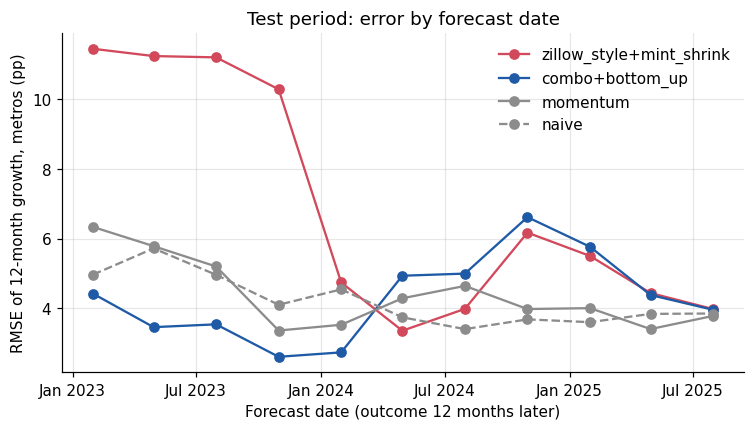

In [4]:
fig, ax = plt.subplots(figsize=(8, 4))
for m, col in [(chosen, COLORS["zillow"]), ("combo+bottom_up", COLORS["ours"]), ("momentum", COLORS["grey"]),
               ("naive", COLORS["grey"])]:
    ax.plot(by_date.index, by_date[m], marker="o", color=col, label=m, ls="--" if m == "naive" else "-")
ax.xaxis.set_major_formatter(mdates.DateFormatter("%b %Y"))
ax.xaxis.set_major_locator(mdates.MonthLocator(bymonth=(1, 7)))
ax.set_ylabel("RMSE of 12-month growth, metros (pp)")
ax.set_xlabel("Forecast date (outcome 12 months later)")
ax.set_title("Test period: error by forecast date")
ax.legend(frameon=False)
save(fig, "05_test_by_date")

The picked method misses badly through 2023, when it carried the 2020-22 boom forward into a market
that had stalled; it wins only once that boom has dropped out of its window. combo+bottom_up does the
opposite: its rate inputs keep it well ahead of momentum through 2023, but from mid-2024 it expects
a recovery that did not come, and the two even out. Both still win at short range, where following
the recent trend is right:

In [5]:
lv_h = ft.rmse_table(test[test["method"].isin([chosen, "combo+bottom_up", "momentum", "naive"])]).unstack("method")
lv_h = lv_h.reindex(["National", "State", "Metro", "County"], level=0)[[chosen, "combo+bottom_up", "momentum", "naive"]]
write_metrics("05_test_by_level", lv_h.reset_index())
lv_h.round(2)

method       zillow_style+mint_shrink  combo+bottom_up  momentum  naive
level    h                                                             
National 1                       0.13             0.09      0.45   0.35
         3                       1.08             0.62      1.19   0.92
         6                       4.25             1.85      1.97   1.58
         12                      8.41             3.82      3.59   2.58
State    1                       0.19             0.14      0.46   0.46
         3                       1.12             0.74      1.24   1.22
         6                       4.00             1.96      2.06   2.07
         12                      7.78             3.93      3.77   3.38
Metro    1                       0.24             0.20      0.54   0.55
         3                       1.26             1.02      1.44   1.47
         6                       4.05             2.42      2.49   2.58
         12                      7.64             4.47      4.50   4.28
County   1                       0.27             0.23      0.59   0.60
         3                       1.36             1.13      1.56   1.58
         6                       4.24             2.66      2.74   2.76
         12                      7.98             4.80      4.92   4.52

### All 26 candidates, metros at 12 months

No candidate passes. The best on the test dates is the no-change forecast; combo+bottom_up ties
momentum. The ranking on 2014-2021 says little about the ranking on 2023-2025.

In [6]:
m12 = res[(res["level"] == "Metro") & (res["h"] == 12) & res["period"].isin(["selection", "test"])]
tab = ft.rmse_table(m12, by=("method", "period")).unstack("period")[["selection", "test"]]
bo_all = ft.rmse_by_origin(m12[m12["period"] == "test"], list(tab.index))
tab["test dates better than momentum"] = [int((bo_all[m] < bo_all["momentum"]).sum()) for m in tab.index]
tab = tab.sort_values("test")
write_metrics("05_all_methods_metro12", tab.reset_index())
del m12, bo_all
tab.round(2)

period,selection,test,test dates better than momentum
method,,,
naive,8.90,4.28,7
combo,5.13,4.42,5
momentum+mint_shrink,5.00,4.43,9
combo+wls_var,5.09,4.45,5
combo+bottom_up,5.06,4.47,5
momentum+bottom_up,5.06,4.49,5
momentum+wls_var,5.06,4.50,5
momentum,5.06,4.50,0
momentum+wls_struct,5.15,4.59,5


### How sure are these differences?

A difference in RMSE is only worth reporting if it is larger than chance. The independent unit
is the forecast date, not the forecast: every metro at one date shares the same national shock,
and 12-month outcomes from quarterly dates overlap (each shares 9 months with the next date). So
for the chosen method against momentum, each date's mean squared error is compared with a
**Diebold-Mariano test** (Newey-West variance over the overlapping dates, with the small-sample
correction), and the skill gets a 95% interval from a **block bootstrap** that resamples runs of
consecutive dates.

In [7]:
pair = res[res["method"].isin(["combo+bottom_up", "momentum"])]
sig_rows = []
for period, sub in [("all 47 dates", pair), ("test, 2023-25", pair[pair["period"] == "test"])]:
    for lv in ["National", "State", "Metro", "County"]:
        for h in (1, 3, 6, 12):
            a = bt.per_date_mse(sub, "combo+bottom_up", lv, h)
            b = bt.per_date_mse(sub, "momentum", lv, h)
            lag = bt.overlap_lag(h)
            stat, p = bt.dm_test(a, b, lag)
            lo, hi = bt.block_bootstrap_skill(a, b, block=max(lag + 1, 2))
            sig_rows.append({"period": period, "level": lv, "h": h, "dates": len(a),
                             "skill": 1 - np.sqrt(a.mean() / b.mean()), "skill_lo95": lo, "skill_hi95": hi,
                             "dm_stat": stat, "dm_p": p})
sig = pd.DataFrame(sig_rows)
write_metrics("05_significance", sig)
del pair
show = sig.assign(**{c: (100 * sig[c]).round(0) for c in ["skill", "skill_lo95", "skill_hi95"]})
show[show["level"].isin(["National", "Metro"])].set_index(["period", "level", "h"])[
    ["skill", "skill_lo95", "skill_hi95", "dm_p"]].round(3)

skill  skill_lo95  skill_hi95   dm_p
period        level    h                                       
all 47 dates  National 1    73.0        59.0        81.0  0.005
                       3    50.0        27.0        64.0  0.023
                       6    32.0         3.0        49.0  0.161
                       12   19.0       -12.0        43.0  0.380
              Metro    1    60.0        52.0        67.0  0.000
                       3    35.0        23.0        45.0  0.001
                       6    21.0         7.0        33.0  0.072
                       12   14.0        -4.0        33.0  0.308
test, 2023-25 National 1    80.0        42.0        88.0  0.076
                       3    48.0       -24.0        67.0  0.103
                       6     6.0       -43.0        37.0  0.802
                       12   -7.0       -69.0        48.0  0.891
              Metro    1    63.0        52.0        69.0  0.006
                       3    29.0         8.0        43.0  0.023
                       6     3.0       -15.0        21.0  0.811
                       12    1.0       -36.0        28.0  0.982

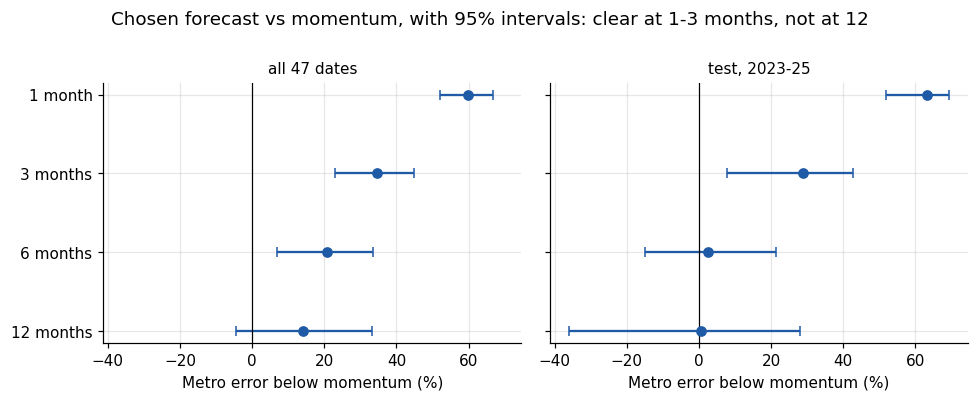

In [8]:
fig, axes = plt.subplots(1, 2, figsize=(9, 3.6), sharey=True, sharex=True)
for ax, period in zip(axes, ["all 47 dates", "test, 2023-25"]):
    d = sig[(sig["period"] == period) & (sig["level"] == "Metro")]
    y = np.arange(len(d))
    ax.errorbar(100 * d["skill"], y, xerr=[100 * (d["skill"] - d["skill_lo95"]), 100 * (d["skill_hi95"] - d["skill"])],
                fmt="o", color=COLORS["ours"], capsize=3)
    ax.axvline(0, color="k", lw=0.8)
    ax.set_yticks(y, [f"{h} month{'s' if h > 1 else ''}" for h in d["h"]])
    ax.set_title(period, fontsize=10)
    ax.set_xlabel("Metro error below momentum (%)")
axes[0].invert_yaxis()
fig.suptitle("Chosen forecast vs momentum, with 95% intervals: clear at 1-3 months, not at 12", y=1.0)
fig.tight_layout()
save(fig, "05_skill_intervals")

The short-range gain is large and clear in both periods. The 12-month gain is not: over all 47
dates its interval includes zero, so the headline "14% below momentum" could be chance. That is
the strongest reason the memo leans on ranking, short horizons and rate stress rather than on the
12-month level.

## 3. Prophet, ETS and ARIMA

Each fits one series at a time on log value: **AutoETS** and **AutoARIMA** from statsforecast
(non-seasonal, since the series is already seasonally adjusted) and **Prophet** (trend only, same
reason). They run on the nation, the 49 states and the 50 largest metros, at the 11 test dates and
every other selection date. They cannot be made to add up across levels, so they are compared with
the reconciled methods on the same 100 series.

**Prophet's settings.** With its defaults Prophet's trend may only bend in the first 80% of the
history, so a forecast made in 2023 carries the 2020-22 boom forward. Two other settings were
compared on 8 selection dates (each January 2014-2021) and the best taken to the test. This was
added after the default scores were seen; the test dates play no part in the choice (see the plan's
addendum).

In [9]:
if (proc / "challengers.parquet").exists() and not use_synthetic():
    ch = pd.read_parquet(proc / "challengers.parquet")            # scripts/run_challengers.py
else:                                                               # small CI run
    full = ft.challenger_series(Y, tags)
    ser = full[:2] + [x for x in full if x.startswith("MSA:")][:2]
    tune_o = ft.tuning_origins(evo)[-2:]
    ch_o = ft.challenger_origins(evo)[[0, -2, -1]]       # one selection date, two test dates
    ch = pd.concat([ft.forecast_challengers(L, ser, tune_o, m) for m in ft.PROPHET_SETTINGS] +
                   [ft.forecast_challengers(L, ser, ch_o, m) for m in ("autoets", "autoarima", "prophet")],
                   ignore_index=True)
ch["method"] = ch["method"].astype(str)
ch["level"] = ft.level_of_id(ch["unique_id"])
tune_dates = ch.loc[ch["method"] == "prophet_cr95", "origin"].unique()
tune = ch[ch["method"].isin(list(ft.PROPHET_SETTINGS)) & ch["origin"].isin(tune_dates)]
tune_tab = ft.rmse_table(tune).groupby("method").mean().sort_values()
prophet_pick = str(tune_tab.index[0])
write_metrics("05_prophet_tuning", tune_tab.rename("avg_rmse_pp").reset_index())
print(f"Prophet setting picked on {len(tune_dates)} selection dates: {prophet_pick} "
      f"({ft.PROPHET_SETTINGS[prophet_pick]})")
tune_tab.round(3).to_frame("average RMSE, 8 selection dates (pp)")

Prophet setting picked on 8 selection dates: prophet_cr95_flex ({'changepoint_range': 0.95, 'changepoint_prior_scale': 0.5})


,"average RMSE, 8 selection dates (pp)"
method,
prophet_cr95_flex,2.236
prophet_cr95,2.243
prophet,3.652


In [10]:
if use_synthetic() and prophet_pick != "prophet":                  # CI: run the picked setting too
    ch = pd.concat([ch, ft.forecast_challengers(L, ser, ch_o, prophet_pick).assign(
        level=lambda d: ft.level_of_id(d["unique_id"]))], ignore_index=True)
ch_methods = list(dict.fromkeys(["autoets", "autoarima", "prophet", prophet_pick]))
ch = ch[ch["method"].isin(ch_methods)]
ch = ch[ch["origin"].isin(ch.loc[ch["method"] == "autoets", "origin"].unique())]
ids, ors = ch["unique_id"].unique(), ch["origin"].unique()
ref = ["naive", "momentum", "combo+bottom_up", chosen]
same = res[res["method"].isin(ref) & res["unique_id"].isin(ids) & res["origin"].isin(ors)]
cmp_ = pd.concat([same[["method", "origin", "h", "unique_id", "pred", "actual"]].astype({"method": str,
                                                                                      "unique_id": str}),
                  ch[["method", "origin", "h", "unique_id", "pred", "actual"]].astype({"unique_id": str})])
cmp_["level"] = ft.level_of_id(cmp_["unique_id"])
cmp_["period"] = ft.period(cmp_["origin"].reset_index(drop=True)).to_numpy()
order = ref + ch_methods
ctab = ft.rmse_table(cmp_, by=("period", "level", "h", "method")).unstack("method")[order]
write_metrics("05_challengers", ctab.reset_index())
ctab.loc["test"].round(2)

method       naive  momentum  combo+bottom_up  zillow_style+mint_shrink  \
level    h                                                                
Metro    1    0.47      0.51             0.12                      0.18   
         3    1.30      1.41             0.75                      1.20   
         6    2.30      2.46             2.15                      4.44   
         12   3.89      4.64             4.92                      8.64   
National 1    0.35      0.45             0.09                      0.13   
         3    0.92      1.19             0.62                      1.08   
         6    1.58      1.97             1.85                      4.25   
         12   2.58      3.59             3.82                      8.41   
State    1    0.46      0.46             0.14                      0.19   
         3    1.22      1.24             0.74                      1.12   
         6    2.07      2.06             1.96                      4.00   
         12   3.38      3.77             3.93                      7.78   

method       autoets  autoarima  prophet  prophet_cr95_flex  
level    h                                                   
Metro    1      0.33       0.10     6.31               1.66  
         3      1.01       0.76     7.57               2.54  
         6      1.95       2.29     9.40               3.68  
         12     3.43       5.11    13.53               6.33  
National 1      0.28       0.07     4.85               1.50  
         3      0.83       0.63     5.69               2.28  
         6      1.63       1.93     6.81               3.22  
         12     2.92       4.39     9.58               5.44  
State    1      0.33       0.12     5.27               1.44  
         3      0.98       0.75     6.24               2.17  
         6      1.78       2.04     7.61               3.02  
         12     2.90       4.12    10.78               5.16

In [11]:
t12 = cmp_[(cmp_["period"] == "test") & (cmp_["level"] == "Metro") & (cmp_["h"] == 12)]
bo_ch = ft.rmse_by_origin(t12, order)
wins = ft.win_counts(bo_ch)
write_metrics("05_challenger_wins", wins.rename("test_dates_better_than_momentum").rename_axis("method").reset_index())
summary = pd.DataFrame({"selection": ctab.loc[("selection", "Metro", 12)], "test": ctab.loc[("test", "Metro", 12)],
                        "test dates better than momentum": wins.reindex(order)}).loc[order]
summary.round(2)

,selection,test,test dates better than momentum
naive,9.37,3.89,7.0
momentum,5.35,4.64,NaN
combo+bottom_up,5.27,4.92,4.0
zillow_style+mint_shrink,5.12,8.64,2.0
autoets,5.12,3.43,10.0
autoarima,5.06,5.11,5.0
prophet,7.43,13.53,0.0
prophet_cr95_flex,5.65,6.33,1.0


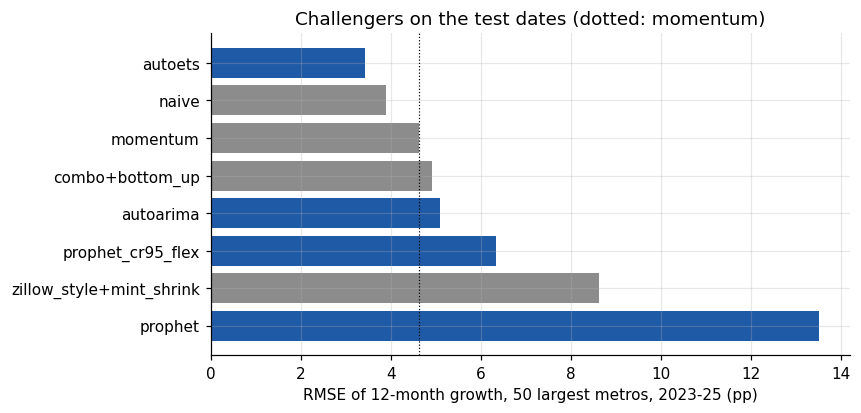

In [12]:
fig, ax = plt.subplots(figsize=(7.5, 3.8))
s = summary["test"].sort_values()
cols = [COLORS["ours"] if m in ("autoets", "autoarima") or m.startswith("prophet") else COLORS["grey"]
        for m in s.index]
ax.barh(s.index, s.to_numpy(), color=cols)
ax.axvline(summary.loc["momentum", "test"], color="k", lw=0.8, ls=":")
ax.set_xlabel("RMSE of 12-month growth, 50 largest metros, 2023-25 (pp)")
ax.set_title("Challengers on the test dates (dotted: momentum)")
ax.invert_yaxis()
save(fig, "05_challengers")

**What the challengers say.**

* **AutoETS** picks a damped trend for almost every series (check below). The trend fades over the
  year instead of running on, which is what 2023-25 rewarded. It is roughly level with the others
  on 2014-2021, so it is a fair candidate, not one chosen for this test.
* **AutoARIMA** behaves like our per-place AR(2): best at 1 month, carries momentum too far at 12.
* **Prophet** is the weakest even after tuning. Its forecast starts from its fitted trend, not from
  the latest value, so it is off from the first month. A model built for daily business series with
  holidays and weekly cycles has no edge on a smoothed monthly price index.

In [13]:
from statsforecast.models import AutoETS

last_test = ft.challenger_origins(evo)[-1]
i = L.index.get_loc(last_test)
with warnings.catch_warnings():
    warnings.simplefilter("ignore")
    kinds = pd.Series([AutoETS(season_length=1).fit(L[s].iloc[: i + 1].to_numpy()).model_["method"]
                       for s in ids]).value_counts()
print(f"AutoETS model types at {last_test:%b %Y} (Ad = damped trend):")
kinds.to_frame("series")

AutoETS model types at Jul 2025 (Ad = damped trend):


,series
"ETS(M,Ad,N)",95
"ETS(A,Ad,N)",4
"ETS(M,A,N)",1


## 4. What this changes

* **The claim gets smaller.** Over all 47 dates the chosen method cut metro 12-month error by 14%
  (notebook 03). Much of that comes from forecasts made in 2022, the rate shock, which this test
  leaves out on purpose. On 2023-2025 nothing beats the no-change forecast at 12 months. What holds
  up is the short range, 1-3 months, where the reconciled models are far ahead at every level.
* **A rule that averages over horizons favours trend-followers** in calm years. The 2014-21 winner
  is the method that broke worst after the turn. The next rule should weight the 12-month horizon
  (what the decisions use) and look at each period on its own, not only on average.
* **Damped ETS becomes a candidate.** It is not declared the winner: it was added after this test
  was seen. It has to earn that on new data.

## 5. The next real test: forecasts frozen today

The forecasts below are made from the last month of data, saved once and never overwritten. They
are scored as Zillow publishes new months: test data that no design choice has seen.

In [14]:
o = L.index[-1]
fwd_path = metrics_dir() / f"05_forward_forecasts_{o:%Y-%m}.csv"
F = models.features(L[list(S_df["unique_id"])], panel.load_macro(), pd.read_parquet(proc / "state_unemp.parquet"),
                    nodes)
now = scenarios.forecast_now(L[list(S_df["unique_id"])], F, tags)
y0 = np.exp(L[list(S_df["unique_id"])].iloc[-1])
counties = list(S_df.columns[1:])
hu = Y.drop_duplicates("unique_id").set_index("unique_id")["hu"]
beta = scenarios.county_betas(L[list(S_df["unique_id"])], counties, weights=hu.reindex(S_df["unique_id"]))
base = scenarios.apply(now["combo"], S_df, y0, beta, pd.Series(0.0, index=scenarios.PATH_H))
fids = list(ids)
rows = []
for h in (1, 3, 6, 12):
    rows.append(pd.DataFrame({"method": "combo+bottom_up", "h": h, "unique_id": fids,
                              "pred_pct": 100 * np.log(base[h].reindex(fids) / y0.reindex(fids)).to_numpy()}))
    rows.append(pd.DataFrame({"method": "momentum", "h": h, "unique_id": fids,
                              "pred_pct": 100 * h / 12 * (L[fids].iloc[-1] - L[fids].iloc[-13]).to_numpy()}))
    rows.append(pd.DataFrame({"method": "naive", "h": h, "unique_id": fids, "pred_pct": 0.0}))
for m in ("autoets", "autoarima", prophet_pick):
    hist = L[fids]
    fc = ft.forecast_paths(hist, m, 12)
    for h in (1, 3, 6, 12):
        rows.append(pd.DataFrame({"method": m, "h": h, "unique_id": fids,
                                  "pred_pct": 100 * (fc[h - 1] - hist.iloc[-1].to_numpy())}))
frozen = pd.concat(rows, ignore_index=True).assign(origin=f"{o:%Y-%m-%d}")
frozen["pred_pct"] = frozen["pred_pct"].round(4)
if not fwd_path.exists():
    frozen.to_csv(fwd_path, index=False)
    print(f"saved {fwd_path.name}")
saved = pd.read_csv(fwd_path)
scored = ft.score_forward(saved, L)
print(f"Forecasts from {o:%B %Y}; months of outcomes so far: {scored['h'].nunique() if len(scored) else 0}")
saved.query("h == 12 and unique_id == 'US'")[["method", "pred_pct"]].round(2)

Forecasts from September 2026; months of outcomes so far: 0


,method,pred_pct
900,combo+bottom_up,3.13
1000,momentum,1.50
1100,naive,0.00
1500,autoets,0.93
1900,autoarima,-0.44
2300,prophet_cr95_flex,1.58
